In [1]:
import os
import time

import requests
import pandas as pd

CITIES = {
    "capetown":     (-33.9249, 18.4241),
    "durban":       (-29.8587, 31.0218),
    "emalahleni":   (-25.8771, 29.2332),
}
START, END = "2022-07-01", "2026-09-25"   # same period as Johannesburg

AQ_URL = "https://air-quality-api.open-meteo.com/v1/air-quality"
WX_URL = "https://archive-api.open-meteo.com/v1/archive"


def year_chunks(start, end):
    s, e = pd.Timestamp(start), pd.Timestamp(end)
    while s <= e:
        c_end = min(s + pd.DateOffset(years=1) - pd.Timedelta(days=1), e)
        yield s.strftime("%Y-%m-%d"), c_end.strftime("%Y-%m-%d")
        s = c_end + pd.Timedelta(days=1)


def fetch(url, hourly_vars, start, end, lat, lon, retries=4):
    params = {
        "latitude": lat, "longitude": lon,
        "hourly": ",".join(hourly_vars),
        "start_date": start, "end_date": end,
        "timezone": "Africa/Johannesburg",
    }
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, params=params, timeout=60)
            if r.status_code == 200:
                return pd.DataFrame(r.json()["hourly"])
            reason = f"status {r.status_code}: {r.text[:150]}"
        except Exception as err:
            reason = f"{type(err).__name__}: {err}"
        print(f"  attempt {attempt} failed ({reason}); waiting...")
        time.sleep(5 * attempt)
    raise RuntimeError(f"Could not download {url} for {start} to {end}")


for name, (lat, lon) in CITIES.items():
    filename = f"{name}_air_quality.csv"
    if os.path.exists(filename):
        print(name, "already downloaded, skipping")
        continue

    print("Downloading", name, "...")
    aq_parts, wx_parts = [], []
    for s, e in year_chunks(START, END):
        aq_parts.append(fetch(AQ_URL, ["pm2_5", "pm10", "nitrogen_dioxide", "ozone"],
                              s, e, lat, lon))
        time.sleep(1)
        wx_parts.append(fetch(WX_URL, ["temperature_2m", "relative_humidity_2m",
                                       "wind_speed_10m", "precipitation",
                                       "surface_pressure"], s, e, lat, lon))
        time.sleep(1)
    df_city = pd.concat(aq_parts).merge(pd.concat(wx_parts), on="time")
    df_city["time"] = pd.to_datetime(df_city["time"])
    daily_city = df_city.set_index("time").resample("D").mean().reset_index()
    daily_city.to_csv(filename, index=False)

    first_valid = daily_city["pm2_5"].first_valid_index()
    print(name, "saved:", len(daily_city), "rows | air quality starts",
          daily_city.loc[first_valid, "time"].date(),
          "| missing pm2_5 days:", int(daily_city["pm2_5"].isna().sum()))

capetown saved: 1548 rows | air quality starts 2022-08-04 | missing pm2_5 days: 34
durban saved: 1548 rows | air quality starts 2022-08-04 | missing pm2_5 days: 34
emalahleni saved: 1548 rows | air quality starts 2022-08-04 | missing pm2_5 days: 34


In [2]:
import pandas as pd

city_files = {
    "Johannesburg": "johannesburg_air_quality.csv",
    "Cape Town": "capetown_air_quality.csv",
    "Durban": "durban_air_quality.csv",
    "Emalahleni": "emalahleni_air_quality.csv",
}

cities = {}
for city, file in city_files.items():
    df_c = pd.read_csv(file, parse_dates=["time"])
    first = df_c["pm2_5"].first_valid_index()
    clean = df_c.loc[first:].reset_index(drop=True)
    cities[city] = clean
    print(f"{city}: {len(df_c)} rows in file | air quality from {clean['time'].min().date()} "
          f"| clean rows {len(clean)} | missing values after cleaning: {int(clean.isna().sum().sum())}")

summary = pd.DataFrame({
    city: {
        "mean PM2.5": d["pm2_5"].mean(),
        "median PM2.5": d["pm2_5"].median(),
        "max PM2.5": d["pm2_5"].max(),
        "mean temp (°C)": d["temperature_2m"].mean(),
        "mean wind (km/h)": d["wind_speed_10m"].mean(),
        "mean pressure (hPa)": d["surface_pressure"].mean(),
    }
    for city, d in cities.items()
}).round(1)

print()
print(summary)

Johannesburg: 1548 rows in file | air quality from 2022-08-04 | clean rows 1514 | missing values after cleaning: 0
Cape Town: 1548 rows in file | air quality from 2022-08-04 | clean rows 1514 | missing values after cleaning: 0
Durban: 1548 rows in file | air quality from 2022-08-04 | clean rows 1514 | missing values after cleaning: 0
Emalahleni: 1548 rows in file | air quality from 2022-08-04 | clean rows 1514 | missing values after cleaning: 0

                     Johannesburg  Cape Town  Durban  Emalahleni
mean PM2.5                   30.3       20.6    14.1        21.4
median PM2.5                 25.3       16.7    12.5        19.6
max PM2.5                   182.2      157.1    52.3        91.3
mean temp (°C)               16.4       17.1    21.0        16.8
mean wind (km/h)             10.4       14.2    12.5        10.0
mean pressure (hPa)         832.6     1015.4  1014.5       845.0


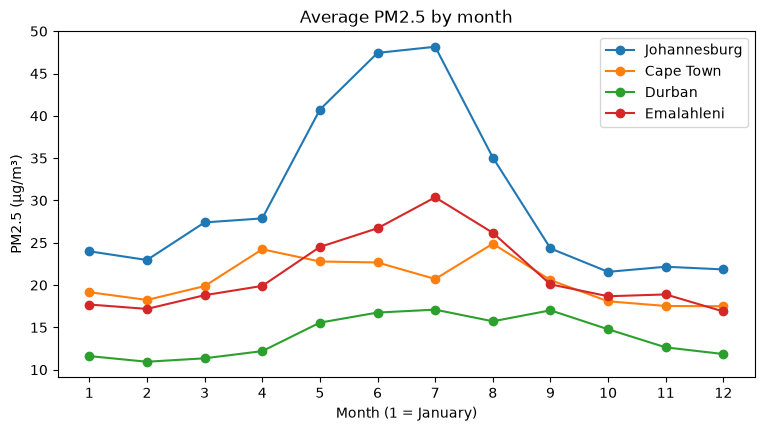

      Johannesburg  Cape Town  Durban  Emalahleni
time                                             
1             24.0       19.2    11.6        17.7
2             23.0       18.2    10.9        17.2
3             27.4       19.9    11.3        18.8
4             27.9       24.2    12.2        19.9
5             40.7       22.8    15.6        24.5
6             47.4       22.7    16.8        26.7
7             48.2       20.7    17.1        30.4
8             35.1       24.9    15.7        26.2
9             24.3       20.6    17.0        20.1
10            21.6       18.1    14.8        18.7
11            22.2       17.5    12.6        18.9
12            21.8       17.5    11.9        16.9

                   Johannesburg  Cape Town  Durban  Emalahleni
corr with wind            -0.57      -0.53   -0.10       -0.55
corr with temp            -0.30       0.01   -0.06       -0.17
today vs tomorrow          0.69       0.42    0.45        0.63


In [3]:
import matplotlib.pyplot as plt

monthly = pd.DataFrame({
    city: d.groupby(d["time"].dt.month)["pm2_5"].mean()
    for city, d in cities.items()
})
monthly.plot(marker="o", figsize=(9, 4.5))
plt.title("Average PM2.5 by month")
plt.xlabel("Month (1 = January)")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(range(1, 13))
plt.show()
print(monthly.round(1))

rows = {}
for city, d in cities.items():
    rows[city] = {
        "corr with wind": d["pm2_5"].corr(d["wind_speed_10m"]),
        "corr with temp": d["pm2_5"].corr(d["temperature_2m"]),
        "today vs tomorrow": d["pm2_5"].corr(d["pm2_5"].shift(-1)),
    }
print()
print(pd.DataFrame(rows).round(2))

In [4]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

features = ["pm2_5", "pm10", "nitrogen_dioxide", "ozone",
            "temperature_2m", "relative_humidity_2m",
            "wind_speed_10m", "precipitation", "surface_pressure", "month"]


def prepare(clean):
    d = clean.copy()
    d["month"] = d["time"].dt.month
    d = d[["time"] + features].copy()
    d["target"] = d["pm2_5"].shift(-1)          # tomorrow's PM2.5
    d = d.dropna().reset_index(drop=True)       # last day has no "tomorrow"
    split = int(len(d) * 0.8)                   # split by time, not randomly
    return d.iloc[:split], d.iloc[split:]


results = []
splits = {}
models = {}
for city, clean in cities.items():
    train, test = prepare(clean)
    splits[city] = (train, test)
    X_train, y_train = train[features], train["target"]
    X_test, y_test = test[features], test["target"]

    preds = {"Baseline": X_test["pm2_5"].values}
    lr = LinearRegression().fit(X_train, y_train)
    preds["Linear Regression"] = lr.predict(X_test)
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                               random_state=42, n_jobs=-1).fit(X_train, y_train)
    preds["Random Forest"] = rf.predict(X_test)
    models[city] = {"Linear Regression": lr, "Random Forest": rf}

    base_mae = mean_absolute_error(y_test, preds["Baseline"])
    for name, p in preds.items():
        mae = mean_absolute_error(y_test, p)
        rmse = np.sqrt(mean_squared_error(y_test, p))
        results.append({
            "City": city,
            "Model": name,
            "MAE": round(mae, 2),
            "RMSE": round(rmse, 2),
            "MAE as % of city mean": round(100 * mae / y_test.mean(), 1),
            "MAE vs baseline": f"{100 * (base_mae - mae) / base_mae:+.0f}%",
        })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

        City             Model   MAE  RMSE  MAE as % of city mean MAE vs baseline
Johannesburg          Baseline 13.34 19.04                   35.8             +0%
Johannesburg Linear Regression 11.68 16.48                   31.3            +12%
Johannesburg     Random Forest 12.05 18.41                   32.3            +10%
   Cape Town          Baseline 11.77 17.69                   49.9             +0%
   Cape Town Linear Regression 10.16 15.53                   43.0            +14%
   Cape Town     Random Forest 10.10 16.23                   42.8            +14%
      Durban          Baseline  4.62  7.14                   35.4             +0%
      Durban Linear Regression  4.12  5.82                   31.5            +11%
      Durban     Random Forest  3.96  5.57                   30.3            +14%
  Emalahleni          Baseline  8.84 11.81                   33.2             +0%
  Emalahleni Linear Regression  7.75 10.70                   29.1            +12%
  Emalahleni    

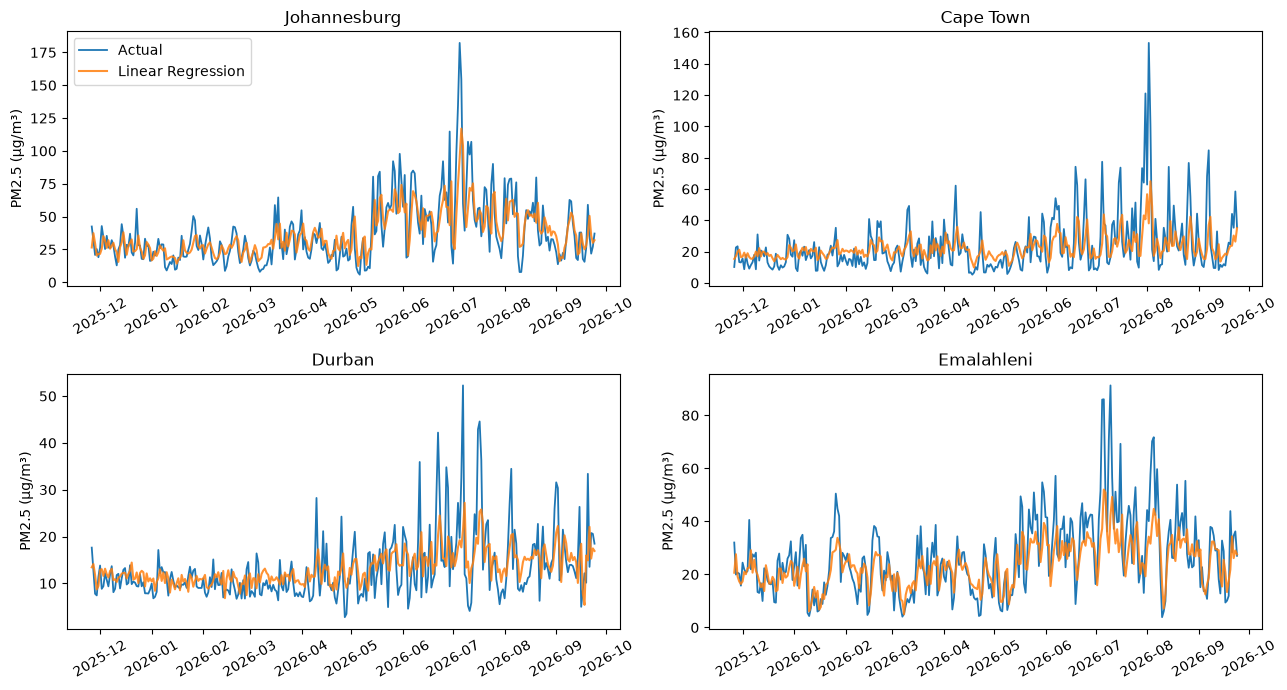

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (city, (train, test)) in zip(axes.ravel(), splits.items()):
    pred = models[city]["Linear Regression"].predict(test[features])
    ax.plot(test["time"], test["target"].values, label="Actual", linewidth=1.3)
    ax.plot(test["time"], pred, label="Linear Regression", alpha=0.85)
    ax.set_title(city)
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

In [6]:
import os
import joblib
from sklearn.metrics import mean_absolute_error

file_keys = {
    "Johannesburg": "johannesburg",
    "Cape Town": "capetown",
    "Durban": "durban",
    "Emalahleni": "emalahleni",
}

for city, (train, test) in splits.items():
    lr = models[city]["Linear Regression"]
    mae = mean_absolute_error(test["target"], lr.predict(test[features]))
    bundle = {
        "city": city,
        "model": lr,
        "features": features,
        "test_mae": float(mae),
    }
    filename = f"airsense_model_{file_keys[city]}.joblib"
    joblib.dump(bundle, filename)
    print(f"{city}: saved {filename} | typical error (MAE) {mae:.2f}")

print()
print(sorted(f for f in os.listdir(".") if f.startswith("airsense_model")))

Johannesburg: saved airsense_model_johannesburg.joblib | typical error (MAE) 11.68
Cape Town: saved airsense_model_capetown.joblib | typical error (MAE) 10.16
Durban: saved airsense_model_durban.joblib | typical error (MAE) 4.12
Emalahleni: saved airsense_model_emalahleni.joblib | typical error (MAE) 7.75

['airsense_model.joblib', 'airsense_model_capetown.joblib', 'airsense_model_durban.joblib', 'airsense_model_emalahleni.joblib', 'airsense_model_johannesburg.joblib']


In [7]:
for city_name, d in cities.items():
    print(city_name, int((d["pm2_5"] > 150).sum()), "days above 150 out of", len(d))

Johannesburg 2 days above 150 out of 1514
Cape Town 2 days above 150 out of 1514
Durban 0 days above 150 out of 1514
Emalahleni 0 days above 150 out of 1514


City: Johannesburg | today = 2026-06-09
Average prediction over the training days: 28.6
Prediction for the next day:               61.8

                   Input  Today's value  Average training day  Effect on tomorrow (µg/m³)
           Today's PM2.5           82.9                  28.6                        35.0
            Today's PM10           83.5                  36.5                        -8.9
              Wind speed            7.9                  10.9                         2.3
           Today's ozone           36.6                  68.4                         2.2
             Temperature           14.0                  16.5                         2.2
                Humidity           41.0                  55.5                         0.8
            Air pressure          832.0                 832.5                        -0.5
Today's nitrogen dioxide           45.6                  32.2                        -0.2
                    Rain            0.0              

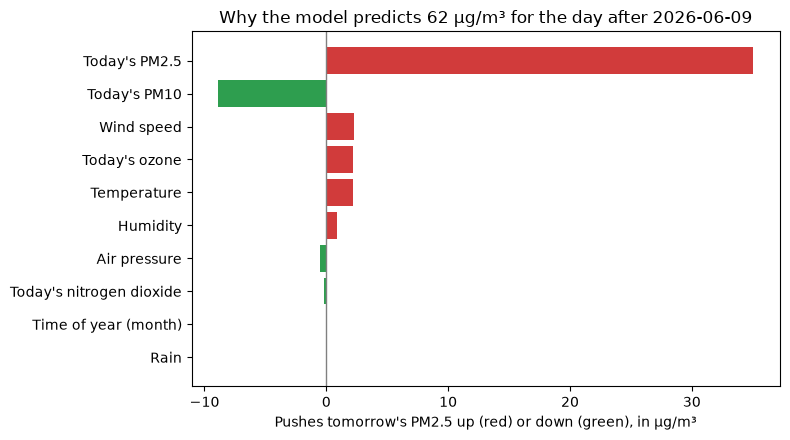

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import shap
    HAVE_SHAP = True
except ImportError:
    HAVE_SHAP = False

labels = {
    "pm2_5": "Today's PM2.5",
    "pm10": "Today's PM10",
    "nitrogen_dioxide": "Today's nitrogen dioxide",
    "ozone": "Today's ozone",
    "temperature_2m": "Temperature",
    "relative_humidity_2m": "Humidity",
    "wind_speed_10m": "Wind speed",
    "precipitation": "Rain",
    "surface_pressure": "Air pressure",
    "month": "Time of year (month)",
}

city_name = "Johannesburg"
today_date = "2026-06-09"     # a date in the test period; the day after it is explained

train, test = splits[city_name]
lr = models[city_name]["Linear Regression"]

row = test[test["time"] == pd.Timestamp(today_date)]
if row.empty:
    raise ValueError("That date is not in this city's test period. Pick another date.")
x = row[features]
today_values = x.iloc[0]
means = train[features].mean()

coefs = pd.Series(lr.coef_, index=features)
contrib = coefs * (today_values - means)          # exact SHAP values for a linear model
base = float(lr.intercept_ + (coefs * means).sum())   # average prediction on training days
pred = float(lr.predict(x)[0])

table = pd.DataFrame({
    "Input": [labels[f] for f in features],
    "Today's value": today_values.round(1).values,
    "Average training day": means.round(1).values,
    "Effect on tomorrow (µg/m³)": contrib.round(1).values,
})
table = table.reindex(table["Effect on tomorrow (µg/m³)"].abs().sort_values(ascending=False).index)

print(f"City: {city_name} | today = {today_date}")
print("Average prediction over the training days:", round(base, 1))
print("Prediction for the next day:              ", round(pred, 1))
print()
print(table.to_string(index=False))
print()
print("Check: average + all effects =", round(base + contrib.sum(), 1), "(should equal the prediction)")

if HAVE_SHAP:
    lib = shap.Explainer(lr, train[features])(x).values[0]
    print("Largest difference from the shap library:", float(np.abs(lib - contrib.values).max()))
else:
    print("The shap library is not installed, so the check against it was skipped.")

order = contrib.abs().sort_values().index
plt.figure(figsize=(8, 4.5))
plt.barh([labels[f] for f in order], contrib[order],
         color=["#d13b3b" if v > 0 else "#2e9e4f" for v in contrib[order]])
plt.axvline(0, color="grey", linewidth=1)
plt.title(f"Why the model predicts {pred:.0f} µg/m³ for the day after {today_date}")
plt.xlabel("Pushes tomorrow's PM2.5 up (red) or down (green), in µg/m³")
plt.tight_layout()
plt.show()

In [9]:
check_rows = []
for name in splits:
    coef = pd.Series(models[name]["Linear Regression"].coef_, index=features)
    check_rows.append({
        "City": name,
        "Month weight": round(coef["month"], 2),
        "Swing Jan to Dec (µg/m³)": round(11 * coef["month"], 1),
        "PM2.5 weight": round(coef["pm2_5"], 2),
        "PM10 weight": round(coef["pm10"], 2),
    })
print(pd.DataFrame(check_rows).to_string(index=False))

        City  Month weight  Swing Jan to Dec (µg/m³)  PM2.5 weight  PM10 weight
Johannesburg         -0.10                      -1.1          0.65        -0.19
   Cape Town         -0.09                      -1.0          0.40        -0.05
      Durban          0.05                       0.6          0.09         0.21
  Emalahleni         -0.02                      -0.3          0.37        -0.04


In [10]:
import os
import shutil

import joblib
import numpy as np
import pandas as pd

file_keys = {
    "Johannesburg": "johannesburg",
    "Cape Town": "capetown",
    "Durban": "durban",
    "Emalahleni": "emalahleni",
}

os.makedirs("model_backups", exist_ok=True)

for city_name, (train, test) in splits.items():
    filename = f"airsense_model_{file_keys[city_name]}.joblib"
    bundle = joblib.load(filename)

    if not np.allclose(bundle["model"].coef_, models[city_name]["Linear Regression"].coef_):
        print(city_name, ": the saved model differs from the one in memory, so nothing was "
              "changed. Re-run the 3A and 3C cells first.")
        continue

    backup = os.path.join("model_backups", filename)
    if not os.path.exists(backup):
        shutil.copy(filename, backup)

    bundle["feature_means"] = {f: float(v) for f, v in train[features].mean().items()}
    bundle["feature_stds"] = {f: float(v) for f, v in train[features].std().items()}
    joblib.dump(bundle, filename)
    print(city_name, ": updated", filename, "| keys now:", sorted(bundle))

# check: rebuild one explanation from the saved file alone
b = joblib.load("airsense_model_johannesburg.joblib")
test_j = splits["Johannesburg"][1]
x = test_j[test_j["time"] == pd.Timestamp("2026-06-09")][b["features"]].iloc[0]
means = pd.Series(b["feature_means"])[b["features"]]
coefs = pd.Series(b["model"].coef_, index=b["features"])
base = float(b["model"].intercept_ + (coefs * means).sum())
pred = float(b["model"].predict(x.to_frame().T)[0])
print("Rebuilt explanation adds up to", round(base + (coefs * (x - means)).sum(), 1),
      "| model prediction", round(pred, 1))

Johannesburg : updated airsense_model_johannesburg.joblib | keys now: ['city', 'feature_means', 'feature_stds', 'features', 'model', 'test_mae']
Cape Town : updated airsense_model_capetown.joblib | keys now: ['city', 'feature_means', 'feature_stds', 'features', 'model', 'test_mae']
Durban : updated airsense_model_durban.joblib | keys now: ['city', 'feature_means', 'feature_stds', 'features', 'model', 'test_mae']
Emalahleni : updated airsense_model_emalahleni.joblib | keys now: ['city', 'feature_means', 'feature_stds', 'features', 'model', 'test_mae']
Rebuilt explanation adds up to 61.8 | model prediction 61.8
